# 03 — Predicting Bad Reviews When the Survey Is Sent

**CRISP-DM phases:** Modeling → Evaluation

**Business problem:** 1–2 star reviews hurt Olist's reputation and conversion. If we can flag orders likely to receive a bad review **on the day Olist sends the satisfaction survey**, customer service can contact those customers first (apology, voucher, fast resolution) *before* they answer.

**Why the survey day?** `review_creation_date` is the day the survey is **sent**, not the day the customer writes the review (`review_answer_timestamp`). Olist sends it the day after delivery, or ~2 days after the promised date if the parcel has not arrived. An earlier version of this notebook predicted "right after delivery" and dropped orders surveyed before delivery, which removed **~75% of late orders**, the biggest source of bad reviews. Predicting on the survey day keeps every order.

**Design decisions (to avoid data leakage)**
| Decision | Choice |
|---|---|
| Target | `is_bad_review` = review score 1 or 2 |
| Prediction moment | The day the survey is sent (`review_ts`) |
| Rows | Every delivered order with a review, Jan 2017 – Aug 2018 |
| Features | Only what is known on the survey day: has the order arrived, how late it is so far; delivery time and carrier time only if it has arrived |
| Seller history | Bad-review rate from reviews **answered** (`answer_ts`) before the survey day |
| Split | **Time-based**: train Jan 2017–Feb 2018, validate Mar–Apr 2018, test May–Aug 2018 |
| Baseline to beat | A simple rule: "contact late orders first" |
| Metrics | PR-AUC and top-10% precision / recall / lift — accuracy is misleading with ~13% positives |

Feature engineering lives in `src/features.py`.

In [1]:
import sys
import warnings
from pathlib import Path

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import shap
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from features import BOOL_FEATURES, CATEGORICAL_FEATURES, FEATURES, NUMERIC_FEATURES, TARGET, build_features

# LightGBM 4.7 deprecates eval_set and shap warns about an output format change;
# neither affects the results, so we hide them to keep the notebook readable.
warnings.filterwarnings("ignore", message=".*eval_set.*")
warnings.filterwarnings("ignore", message=".*TreeExplainer shap values output.*")

FIG_DIR = PROJECT_ROOT / "reports" / "figures"
DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

GREY, RED, BLUE, DARK, GREEN, SAND = "#B0B7BF", "#D1495B", "#2E86AB", "#2B2D42", "#81B29A", "#F2CC8F"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.titlelocation": "left",
    "font.size": 10,
})


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


orders = pd.read_parquet(DATA_DIR / "orders.parquet")
df = build_features(orders)
print(f"Modelling rows: {len(df):,} | bad-review rate: {df[TARGET].mean():.1%}")

Modelling rows: 95,560 | bad-review rate: 12.8%


## 1. Time-based split

We train on the past and evaluate on the future, exactly as the model would be used. A random split would mix months and give optimistic results (e.g. the model could learn a seller's behaviour from orders that happen *after* the test orders).

In [2]:
train = df[df["purchase_ts"] < "2018-03-01"]
valid = df[(df["purchase_ts"] >= "2018-03-01") & (df["purchase_ts"] < "2018-05-01")]
test = df[df["purchase_ts"] >= "2018-05-01"]

X_train, y_train = train[FEATURES], train[TARGET].to_numpy()
X_valid, y_valid = valid[FEATURES], valid[TARGET].to_numpy()
X_test, y_test = test[FEATURES], test[TARGET].to_numpy()

pd.DataFrame({
    "rows": [len(train), len(valid), len(test)],
    "bad_review_rate": [y_train.mean(), y_valid.mean(), y_test.mean()],
    "from": [train["purchase_ts"].min().date(), valid["purchase_ts"].min().date(), test["purchase_ts"].min().date()],
    "to": [train["purchase_ts"].max().date(), valid["purchase_ts"].max().date(), test["purchase_ts"].max().date()],
}, index=["train", "valid", "test"]).round(3)

,rows,bad_review_rate,from,to
train,56618,0.131,2017-01-05,2018-02-28
valid,13700,0.165,2018-03-01,2018-04-30
test,25242,0.100,2018-05-01,2018-08-29


## 2. Evaluation helpers

- **PR-AUC (average precision)**: area under the precision–recall curve. A random model scores ≈ the positive rate (~0.10 in the test months), so that is the bar to beat.
- **ROC-AUC**: probability that a random bad-review order gets a higher score than a random good one (0.5 = random).
- **Top-10% metrics** (the business view): if customer service can only contact 10% of orders, how many of the contacted orders are truly at risk (**precision**), what share of all bad reviews they reach (**recall**), and how much better than random that is (**lift**).

In [3]:
def top_k(y, proba, frac=0.10):
    n = int(len(y) * frac)
    top = np.argsort(-proba)[:n]
    precision = y[top].mean()
    return {"precision@10%": precision, "recall@10%": y[top].sum() / y.sum(), "lift@10%": precision / y.mean()}


def evaluate(name, y, proba):
    return {
        "model": name,
        "accuracy@0.5": accuracy_score(y, proba >= 0.5),
        "ROC-AUC": roc_auc_score(y, proba),
        "PR-AUC": average_precision_score(y, proba),
        **top_k(y, proba),
    }

## 3. Models, from simplest to strongest

Each model must beat the previous one to justify its complexity.

In [4]:
num_cols = NUMERIC_FEATURES + BOOL_FEATURES

# Linear models need: no missing values, numbers on similar scales, one-hot categories
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100), CATEGORICAL_FEATURES),
])

# Trees split on thresholds, so they do not need scaling. Without it, the tree's
# rules stay in real units (e.g. "n_items <= 1.5") and are easy to read.
preprocess_tree = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100), CATEGORICAL_FEATURES),
])

class LateRule:
    """Business-rule baseline: late orders first, the later the riskier.

    No learning: the score is 0.5 + a bit for late orders, below 0.5 for on-time
    ones, ordered by how many days late the order is on the survey day.
    """
    def fit(self, X, y):
        return self

    def predict_proba(self, X):
        days = X["days_late_at_survey"].clip(-60, 60).to_numpy()
        score = 0.5 * X["is_late"].to_numpy() + 0.5 * (days + 60) / 121
        return np.column_stack([1 - score, score])


models = {
    # 1) Baselines: the training bad-review rate for everyone, and a simple business rule
    "Dummy (base rate)": DummyClassifier(strategy="prior"),
    "Rule: late first": LateRule(),
    # 2) Logistic regression; class_weight="balanced" gives the rare class more weight
    "Logistic regression": Pipeline([("prep", preprocess),
                                     ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    # 3) Shallow decision tree: easy to read, the model from the DATA 5503 course
    "Decision tree (depth 5)": Pipeline([("prep", preprocess_tree),
                                         ("clf", DecisionTreeClassifier(max_depth=5, min_samples_leaf=200,
                                                                        class_weight="balanced", random_state=42))]),
}

valid_scores, fitted = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    valid_scores.append(evaluate(name, y_valid, model.predict_proba(X_valid)[:, 1]))
pd.DataFrame(valid_scores).set_index("model").round(3)

,accuracy@0.5,ROC-AUC,PR-AUC,precision@10%,recall@10%,lift@10%
model,,,,,,
Dummy (base rate),0.835,0.500,0.165,0.180,0.109,1.085
Rule: late first,0.874,0.719,0.476,0.730,0.441,4.411
Logistic regression,0.788,0.814,0.574,0.755,0.457,4.566
Decision tree (depth 5),0.779,0.812,0.564,0.764,0.462,4.618


**The accuracy trap:** the dummy model scores ~84–90% accuracy while being useless — it never flags a single order. The models trained with `class_weight="balanced"` have *lower* accuracy because they deliberately flag more orders to catch the rare class. This is why accuracy is the wrong metric for imbalanced problems.

### LightGBM (gradient-boosted trees)

Hundreds of small trees, each correcting the errors of the previous ones. It handles missing values and categories natively, so it needs no preprocessing. We tune two settings on the **validation** set and use **early stopping** (stop adding trees when validation PR-AUC stops improving) to avoid overfitting.

In [5]:
def fit_lgbm(X_tr, y_tr, X_va, y_va, num_leaves, min_child_samples):
    model = lgb.LGBMClassifier(
        n_estimators=3000, learning_rate=0.03,
        num_leaves=num_leaves, min_child_samples=min_child_samples,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
        random_state=42, verbose=-1,
    )
    model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], eval_metric="average_precision",
              callbacks=[lgb.early_stopping(100, verbose=False)])
    return model


grid = []
for num_leaves in [15, 31, 63]:
    for min_child_samples in [20, 100]:
        m = fit_lgbm(X_train, y_train, X_valid, y_valid, num_leaves, min_child_samples)
        ap = average_precision_score(y_valid, m.predict_proba(X_valid)[:, 1])
        grid.append({"num_leaves": num_leaves, "min_child_samples": min_child_samples,
                     "trees": m.best_iteration_, "valid PR-AUC": ap, "model": m})
grid = pd.DataFrame(grid)
best = grid.loc[grid["valid PR-AUC"].idxmax()]
lgbm = best["model"]
fitted["LightGBM"] = lgbm
valid_scores.append(evaluate("LightGBM", y_valid, lgbm.predict_proba(X_valid)[:, 1]))

print(f"Best: num_leaves={best['num_leaves']}, min_child_samples={best['min_child_samples']}, trees={best['trees']}")
grid.drop(columns="model").round(4)

Best: num_leaves=15, min_child_samples=20, trees=169


,num_leaves,min_child_samples,trees,valid PR-AUC
0,15,20,169,0.5981
1,15,100,202,0.5972
2,31,20,54,0.5949
3,31,100,57,0.5952
4,63,20,69,0.5945
5,63,100,118,0.5929


In [6]:
pd.DataFrame(valid_scores).set_index("model").round(3)

,accuracy@0.5,ROC-AUC,PR-AUC,precision@10%,recall@10%,lift@10%
model,,,,,,
Dummy (base rate),0.835,0.500,0.165,0.180,0.109,1.085
Rule: late first,0.874,0.719,0.476,0.730,0.441,4.411
Logistic regression,0.788,0.814,0.574,0.755,0.457,4.566
Decision tree (depth 5),0.779,0.812,0.564,0.764,0.462,4.618
LightGBM,0.887,0.819,0.598,0.768,0.464,4.640


### Ablation: how much does the seller's history add?

We retrain LightGBM without the two seller-history features. If PR-AUC drops, the feature carries real signal.

In [7]:
seller_cols = ["seller_prior_reviews", "seller_prior_bad_rate"]
no_seller = [c for c in FEATURES if c not in seller_cols]
m_ns = fit_lgbm(X_train[no_seller], y_train, X_valid[no_seller], y_valid,
                best["num_leaves"], best["min_child_samples"])
ap_ns = average_precision_score(y_valid, m_ns.predict_proba(X_valid[no_seller])[:, 1])
print(f"Valid PR-AUC with seller history:    {best['valid PR-AUC']:.3f}")
print(f"Valid PR-AUC without seller history: {ap_ns:.3f}")

Valid PR-AUC with seller history:    0.598
Valid PR-AUC without seller history: 0.594


## 4. Final evaluation on the test set (May–Aug 2018)

The test set is used **once**, after every modelling choice was made on validation. Using it earlier would leak information into our decisions.

In [8]:
test_proba = {name: m.predict_proba(X_test)[:, 1] for name, m in fitted.items()}
test_scores = pd.DataFrame([evaluate(n, y_test, p) for n, p in test_proba.items()]).set_index("model")
test_scores.round(3)

,accuracy@0.5,ROC-AUC,PR-AUC,precision@10%,recall@10%,lift@10%
model,,,,,,
Dummy (base rate),0.900,0.500,0.100,0.101,0.101,1.014
Rule: late first,0.897,0.571,0.209,0.240,0.240,2.404
Logistic regression,0.833,0.725,0.323,0.373,0.373,3.727
Decision tree (depth 5),0.811,0.716,0.302,0.356,0.356,3.561
LightGBM,0.907,0.725,0.338,0.377,0.377,3.771


### Robustness checks

1. **Does the model only rediscover "late = bad"?** We score the orders that were already **delivered on the survey day** (the old "after delivery" problem). Here lateness is no longer the whole story.
2. **Censoring at the end of the data.** The data stop in October 2018, so slow orders bought in Jul–Aug 2018 may be missing (not delivered yet) and the test months look better than they are. We re-score on **May–Jun 2018 only**, which are less affected.

In [9]:
delivered = (X_test["delivered_at_survey"] == 1).to_numpy()
early_test = (test["purchase_ts"] < "2018-07-01").to_numpy()

rows = []
for name in ["Rule: late first", "Logistic regression", "LightGBM"]:
    p = test_proba[name]
    rows.append({"model": name,
                 "PR-AUC (all test)": average_precision_score(y_test, p),
                 "PR-AUC (delivered by survey day)": average_precision_score(y_test[delivered], p[delivered]),
                 "PR-AUC (May–Jun only)": average_precision_score(y_test[early_test], p[early_test])})
print(f"Delivered by survey day: {delivered.mean():.1%} of test orders, bad-review rate {y_test[delivered].mean():.1%}")
print(f"May–Jun bad-review rate: {y_test[early_test].mean():.1%} vs Jul–Aug {y_test[~early_test].mean():.1%}")
monthly_late = df.groupby(df["purchase_ts"].dt.to_period("M"))[["is_late", TARGET]].mean().loc["2018-01":]
display(pd.DataFrame(rows).set_index("model").round(3))
monthly_late.round(3)

Delivered by survey day: 97.2% of test orders, bad-review rate 8.5%
May–Jun bad-review rate: 10.4% vs Jul–Aug 9.6%


,PR-AUC (all test),PR-AUC (delivered by survey day),PR-AUC (May–Jun only)
model,,,
Rule: late first,0.209,0.089,0.210
Logistic regression,0.323,0.199,0.328
LightGBM,0.338,0.205,0.337


,is_late,is_bad_review
purchase_ts,,
2018-01,0.056,0.137
2018-02,0.139,0.194
2018-03,0.186,0.212
2018-04,0.044,0.118
2018-05,0.065,0.108
2018-06,0.012,0.100
2018-07,0.033,0.097
2018-08,0.061,0.095


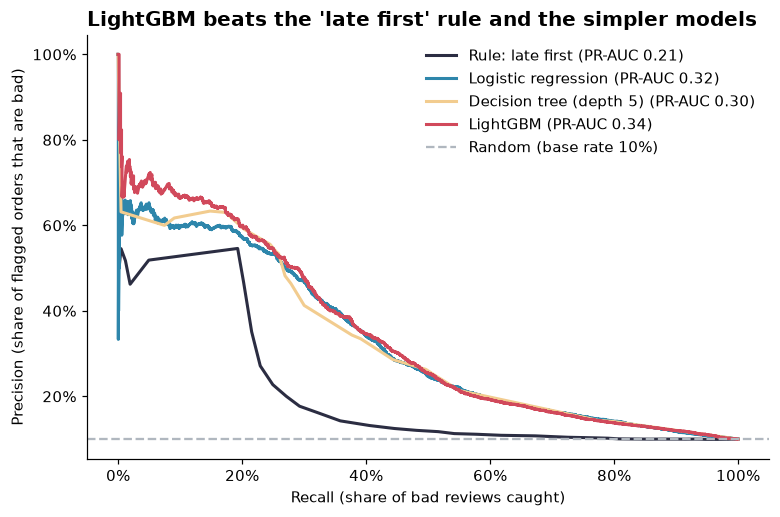

In [10]:
colors = {"Dummy (base rate)": GREY, "Rule: late first": DARK, "Logistic regression": BLUE,
          "Decision tree (depth 5)": SAND, "LightGBM": RED}

fig, ax = plt.subplots(figsize=(8, 5))
for name, proba in test_proba.items():
    if name.startswith("Dummy"):
        continue
    p, r, _ = precision_recall_curve(y_test, proba)
    ax.plot(r, p, color=colors[name], lw=2,
            label=f"{name} (PR-AUC {average_precision_score(y_test, proba):.2f})")
ax.axhline(y_test.mean(), color=GREY, ls="--", label=f"Random (base rate {y_test.mean():.0%})")
ax.set_xlabel("Recall (share of bad reviews caught)")
ax.set_ylabel("Precision (share of flagged orders that are bad)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("LightGBM beats the 'late first' rule and the simpler models")
ax.legend(frameon=False)
save(fig, "12_precision_recall_curves")
plt.show()

### Business view: who should customer service contact?

The **capture curve** sorts orders from highest to lowest predicted risk and shows what share of all bad reviews we reach by contacting the top X% of orders.

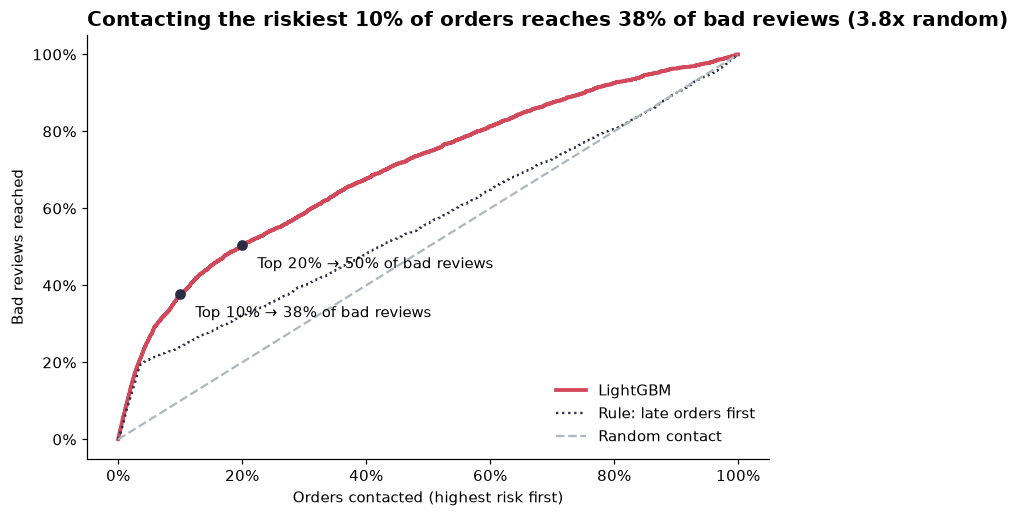

Top 10% → 37.7%, top 20% → 50.4% of bad reviews


In [11]:
proba = test_proba["LightGBM"]
order = np.argsort(-proba)
captured = np.cumsum(y_test[order]) / y_test.sum()
contacted = np.arange(1, len(y_test) + 1) / len(y_test)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(contacted, captured, color=RED, lw=2.5, label="LightGBM")
rule_order = np.argsort(-test_proba["Rule: late first"])
ax.plot(contacted, np.cumsum(y_test[rule_order]) / y_test.sum(), color=DARK, lw=1.5, ls=":",
        label="Rule: late orders first")
ax.plot([0, 1], [0, 1], color=GREY, ls="--", label="Random contact")
for frac in [0.10, 0.20]:
    k = int(len(y_test) * frac) - 1
    ax.scatter(contacted[k], captured[k], color=DARK, zorder=3)
    ax.annotate(f"Top {frac:.0%} → {captured[k]:.0%} of bad reviews",
                (contacted[k], captured[k]), xytext=(10, -15), textcoords="offset points")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Orders contacted (highest risk first)")
ax.set_ylabel("Bad reviews reached")
k10 = int(len(y_test) * 0.10) - 1
ax.set_title(f"Contacting the riskiest 10% of orders reaches {captured[k10]:.0%} of bad reviews "
             f"({captured[k10] / 0.10:.1f}x random)")
ax.legend(frameon=False, loc="lower right")
save(fig, "13_capture_curve")
plt.show()
print(f"Top 10% → {captured[int(len(y_test) * 0.10) - 1]:.1%}, top 20% → {captured[int(len(y_test) * 0.20) - 1]:.1%} of bad reviews")

### Choosing a decision threshold

The model outputs a probability; the team needs a yes/no. We pick the threshold that maximises F1 **on validation**, then check it on test.

In [12]:
p_val = lgbm.predict_proba(X_valid)[:, 1]
prec, rec, thr = precision_recall_curve(y_valid, p_val)
f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
threshold = thr[np.argmax(f1)]

pred = (proba >= threshold).astype(int)
cm = pd.DataFrame(confusion_matrix(y_test, pred),
                  index=["Actual: good", "Actual: bad"], columns=["Predicted: good", "Predicted: bad"])
print(f"Threshold (chosen on validation): {threshold:.3f}")
print(f"Test → precision {precision_score(y_test, pred):.1%}, recall {recall_score(y_test, pred):.1%}, "
      f"F1 {f1_score(y_test, pred):.3f}, flagged {pred.mean():.1%} of orders")
cm

Threshold (chosen on validation): 0.324
Test → precision 52.4%, recall 26.5%, F1 0.352, flagged 5.1% of orders


,Predicted: good,Predicted: bad
Actual: good,22109,608
Actual: bad,1856,669


## 5. What drives the predictions?

### The decision tree (readable rules)

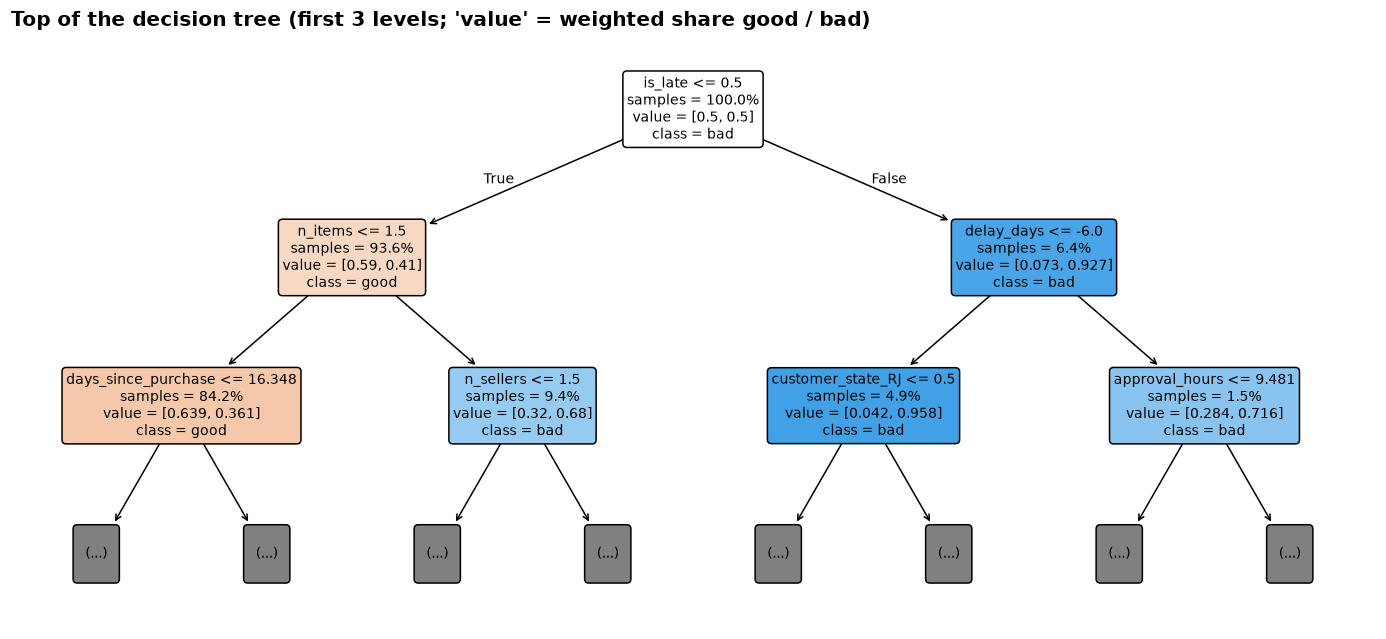

In [13]:
tree = fitted["Decision tree (depth 5)"]
feature_names = [n.split("__", 1)[1] for n in tree.named_steps["prep"].get_feature_names_out()]

fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(tree.named_steps["clf"], max_depth=2, feature_names=feature_names,
          class_names=["good", "bad"], filled=True, impurity=False, proportion=True,
          rounded=True, fontsize=9, ax=ax)
ax.set_title("Top of the decision tree (first 3 levels; 'value' = weighted share good / bad)")
save(fig, "14_decision_tree")
plt.show()

### SHAP values for LightGBM

SHAP splits each prediction into contributions from each feature. In the plot, every dot is an order: position = how much that feature pushed the risk up (right) or down (left); colour = the feature's value (red = high, blue = low). Categorical features have no natural high/low, so their colour is not meaningful.

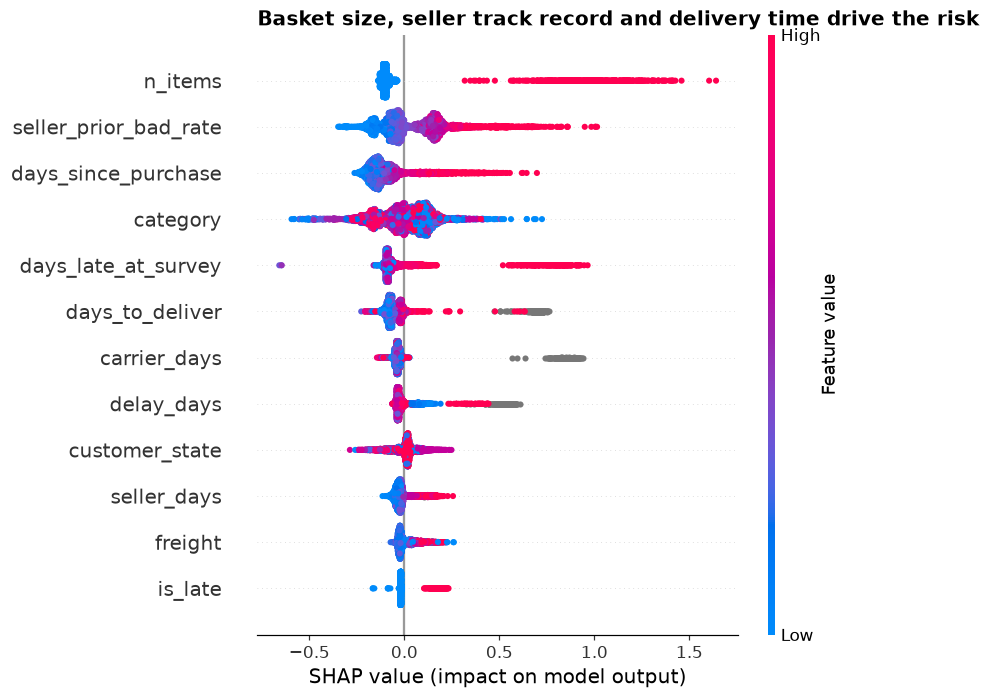

,feature,mean_abs_shap
0,n_items,0.1925
1,seller_prior_bad_rate,0.1386
2,days_since_purchase,0.1369
3,category,0.1099
4,days_late_at_survey,0.1071
5,days_to_deliver,0.0772
6,carrier_days,0.0595
7,delay_days,0.0508
8,customer_state,0.0453
9,seller_days,0.0407


In [14]:
sample = X_test.sample(5000, random_state=42)
explainer = shap.TreeExplainer(lgbm)
shap_values = explainer.shap_values(sample)
if isinstance(shap_values, list):      # older shap versions return one array per class
    shap_values = shap_values[1]

display_sample = sample.copy()
for col in CATEGORICAL_FEATURES:       # colour needs numbers; categories become codes
    display_sample[col] = display_sample[col].cat.codes

shap.summary_plot(shap_values, display_sample, max_display=12, show=False)
fig = plt.gcf()
fig.axes[0].set_title("Basket size, seller track record and delivery time drive the risk",
                      loc="left", fontweight="bold")
save(fig, "15_shap_summary")
plt.show()

importance = (
    pd.DataFrame({"feature": FEATURES, "mean_abs_shap": np.abs(shap_values).mean(axis=0)})
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)
importance.head(12).round(4)

### A finding the model surfaced: multi-item and multi-seller orders

SHAP ranks `n_items` first, ahead of delivery time. Let us check it directly in the data.

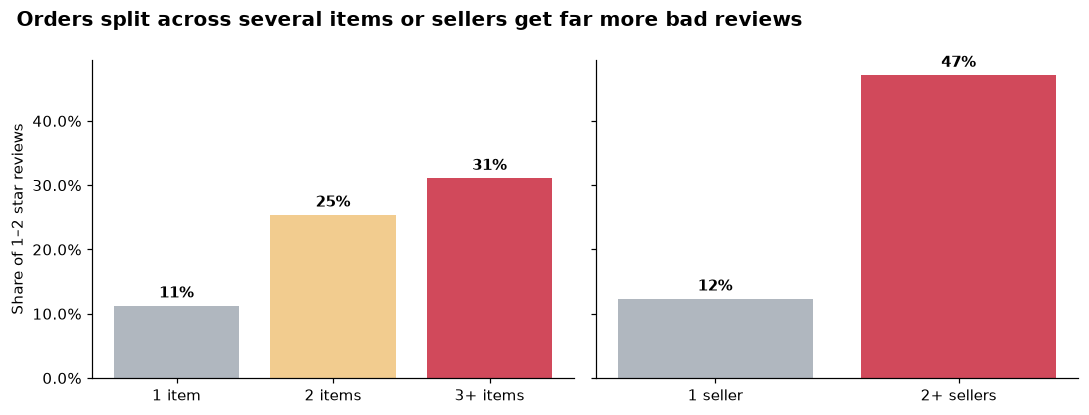

Multi-seller orders delivered ON TIME still get 47% bad reviews


,orders,bad_review_rate
1 item,86061,0.113
2 items,7300,0.254
3+ items,2199,0.311
1 seller,94302,0.123
2+ sellers,1258,0.471


In [15]:
basket = df.assign(
    items=pd.cut(df["n_items"], [0, 1, 2, np.inf], labels=["1 item", "2 items", "3+ items"]),
    sellers=np.where(df["n_sellers"] >= 2, "2+ sellers", "1 seller"),
)
by_items = basket.groupby("items", observed=True)[TARGET].agg(orders="size", bad_review_rate="mean")
by_sellers = basket.groupby("sellers")[TARGET].agg(orders="size", bad_review_rate="mean")
on_time_multi = basket.loc[(basket["sellers"] == "2+ sellers") & (basket["is_late"] == 0), TARGET].mean()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, tbl, cols in [(axes[0], by_items, [GREY, SAND, RED]), (axes[1], by_sellers, [GREY, RED])]:
    bars = ax.bar(tbl.index.astype(str), tbl["bad_review_rate"], color=cols)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in tbl["bad_review_rate"]], padding=3, fontweight="bold")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[0].set_ylabel("Share of 1–2 star reviews")
fig.suptitle("Orders split across several items or sellers get far more bad reviews",
             x=0.02, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "16_bad_reviews_by_basket")
plt.show()

print(f"Multi-seller orders delivered ON TIME still get {on_time_multi:.0%} bad reviews")
pd.concat([by_items, by_sellers]).round(3)

**Hypothesis:** items from different sellers ship separately. The order is marked "delivered" when one parcel arrives, so the customer may review while still missing products. Phase 5 (review text) can test this by looking for complaints like *"não recebi"* ("I did not receive").

## 6. Save artefacts for the dashboard

In [16]:
joblib.dump(lgbm, MODEL_DIR / "bad_review_lgbm.joblib")

test_out = test[["order_id", "purchase_ts"]].assign(is_bad_review=y_test, risk=proba)
test_out.to_parquet(DATA_DIR / "test_predictions.parquet", index=False)
importance.to_parquet(DATA_DIR / "shap_importance.parquet", index=False)
test_scores.reset_index().to_parquet(DATA_DIR / "model_scores.parquet", index=False)
print("Saved model, test predictions, SHAP importance and model scores")

Saved model, test predictions, SHAP importance and model scores


## Key findings

1. **Fixing the prediction moment was the biggest improvement.** `review_creation_date` is when the survey is **sent**, not when the customer answers. The first version predicted "after delivery" and dropped every order surveyed before delivery, which threw away ~75% of late orders. Predicting on the survey day keeps them, and test PR-AUC went from **0.21 to 0.34**.
2. **The model beats the obvious rule.** On the unseen test months (May–Aug 2018) LightGBM reaches PR-AUC **0.34** vs **0.21** for "contact late orders first" and **0.10** for random. Contacting the riskiest **10%** of orders reaches **38%** of all bad reviews (lift ≈ **3.8x**), vs 24% with the rule.
3. **It is not just "late = bad".** On orders already delivered by the survey day, where lateness explains little, the model still scores PR-AUC **0.20** vs 0.09 for the rule, the same as the first version on that population.
4. **Logistic regression is almost as good** (PR-AUC 0.32, same ROC-AUC 0.725). We keep LightGBM for the dashboard because it handles the missing delivery fields of not-yet-delivered orders natively and is slightly better on the top 10%, but logistic regression is a defensible, more explainable choice.
5. **Top drivers (SHAP): basket size, the seller's past bad-review rate, time since purchase and days late so far.** The seller history adds only a small gain (validation PR-AUC 0.595 → 0.599).
6. **Split orders.** Orders with 2+ sellers get **47%** bad reviews **even when delivered on time** (vs 12% for single-seller orders); 3+ item orders get 31%. Likely cause: items ship separately and the order is marked delivered before everything arrives.
7. **Validation → test drop** (PR-AUC 0.60 → 0.34) is mostly a change in the mix: Feb–Mar 2018 had a spike of late orders (14–19%), the test months very few (1–7%), and late orders are the easy ones. Censoring at the end of the data matters little: May–Jun alone gives the same PR-AUC (0.34).

**Limitations:** the dataset contains only orders that were eventually delivered, which on the survey day is not yet known for late orders; and many bad reviews come from things not in the structured data (product quality, wrong item). Phase 5 uses the review **text** to see what customers actually complain about.

**Business recommendations**
- On the day the survey goes out, **prioritise proactive customer-service contacts** with the risk score (top 10–20% of orders), not just late orders.
- **Fix split shipments:** show customers clearly when an order arrives in several parcels, and only mark an order as delivered when every parcel has arrived.
- **Monitor sellers** with a high past bad-review rate.
5. **Validation (0.60) vs test (0.34) PR-AUC is not overfitting.** The validation months (Mar–Apr 2018) include a delivery crisis: 19% of March orders were late vs 1–7% in the test months. The "late first" rule drops the same way (0.48 → 0.21).
6. **`is_late` is measured on the survey day.** For ~280 orders surveyed while still in transit *before* their promised day, the final `is_late` (mostly "on time") would leak the future, so they count as not late yet. `src/features.py` asserts this.